#### ✅ 단순 선형회귀 모델에 실제 데이터를 적용해서 테스트 해보기

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

data = {
    "area": [
        30, 35, 40, 45, 50,
        55, 60, 65, 70, 75,
        80, 85, 90, 95, 100
    ],
    "price": [
        150, 170, 190, 210, 230,
        250, 280, 290, 320, 340,
        370, 390, 410, 430, 460
    ]
}

df = pd.DataFrame(data)

# Feature와 Target 설정
X = df[["area"]]
y = df["price"]

# 학습 데이터와 테스트 데이터 분리
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# 선형회귀 모델 생성 및 학습
model = LinearRegression()
model.fit(X_train, y_train)

print(f"학습된 모델의 회귀계수 : {model.coef_}")
print(f"학습된 모델의 절편 : {model.intercept_}")

# 테스트 데이터로 예측
y_pred = model.predict(X_test)

# Acutal : 실제 값
# Predicted : 예측 값
# Residual(잔차) : 실제 값과 예측 값의 차이
result = pd.DataFrame({
    "Actual" : y_test.to_numpy(),
    "Predicted" : y_pred,
    "Residual" : y_test.to_numpy() - y_pred
})

result

학습된 모델의 회귀계수 : [4.45594627]
학습된 모델의 절편 : 9.340181746345365


,Actual,Predicted,Residual
0,340,343.536152,-3.536152
1,390,388.095614,1.904386
2,150,143.018570,6.981430


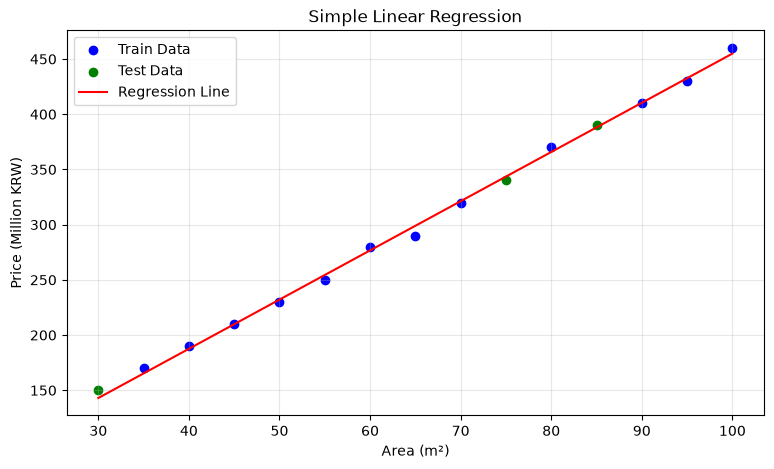

In [9]:
# 회귀선 시각화하기
# 회귀선을 그릴 x값 생성
X_line = pd.DataFrame({
    "area": np.linspace(
        X["area"].min(),
        X["area"].max(),
        100
    )
})

# 회귀선에 해당하는 예측값
y_line = model.predict(X_line)

plt.figure(figsize=(9, 5))

# 학습 데이터
plt.scatter(
    X_train["area"],
    y_train,
    label="Train Data",
    color="blue"
)

# 테스트 데이터
plt.scatter(
    X_test["area"],
    y_test,
    label="Test Data",
    color="green"
)

# 회귀선
plt.plot(
    X_line["area"],
    y_line,
    color="red",
    label="Regression Line"
)

plt.xlabel("Area (m²)")
plt.ylabel("Price (Million KRW)")
plt.title("Simple Linear Regression")
plt.legend()
plt.grid(alpha=0.3)

plt.show()